#Leukemia Transcriptomics AI Classifier

**Biological Problem:** Acute Lymphoblastic Leukemia (ALL) and Acute Myeloid Leukemia (AML) require completely different chemotherapy regimens. However, they are difficult to distinguish under a microscope. By looking at a patient's Gene Expression Profile, we can use AI to classify the cancer based on a systems-level biological signature.

**Dataset:** The Golub et al. (1999) Leukemia dataset. Contains expression levels of 7,129 genes from 72 patients.

**Objective:**
1. **PCA:** Reduce the 7,129 gene features down to 2 principal components to visualize the disease separation.
2. **K-Means Clustering:** See if unsupervised AI can naturally group the patients.
3. **Random Forest Classifier:** Train a model to accurately predict ALL vs. AML.

### 1. Import Libraries and Preprocess the Data


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
import os
import zipfile

# Automatically unzip archive.zip if it exists and the dataset is not yet unpacked
if os.path.exists('archive.zip') and not all(os.path.exists(f) for f in ['data_set_ALL_AML_train.csv', 'data_set_ALL_AML_independent.csv', 'actual.csv']):
    print("Extracting archive.zip...")
    with zipfile.ZipFile('archive.zip', 'r') as zip_ref:
        zip_ref.extractall('.')

# Required files
required_files = ['data_set_ALL_AML_train.csv', 'data_set_ALL_AML_independent.csv', 'actual.csv']
missing_files = [f for f in required_files if not os.path.exists(f)]

if missing_files:
    raise FileNotFoundError(
        f"ERROR: Missing required files: {missing_files}. "
        "Please upload these CSV files (or the archive.zip containing them) to your Colab session."
    )

# Load data
train_data = pd.read_csv('data_set_ALL_AML_train.csv')
test_data = pd.read_csv('data_set_ALL_AML_independent.csv')
labels = pd.read_csv('actual.csv')

# Clean and transpose data
train_cols = [col for col in train_data.columns if "call" not in col]
test_cols = [col for col in test_data.columns if "call" not in col]

train_data = train_data[train_cols]
test_data = test_data[test_cols]

# Set Gene Accession Number as index and transpose so patients are rows
train_data.set_index('Gene Accession Number', inplace=True)
test_data.set_index('Gene Accession Number', inplace=True)

# Drop the Gene Description column before transposing
train_data.drop('Gene Description', axis=1, inplace=True)
test_data.drop('Gene Description', axis=1, inplace=True)

X_train = train_data.T
X_test = test_data.T

# Convert patient ID strings to integers to match the labels dataframe
X_train.index = pd.to_numeric(X_train.index)
X_test.index = pd.to_numeric(X_test.index)

# Merge labels
X_train = X_train.merge(labels, left_index=True, right_on='patient')
X_test = X_test.merge(labels, left_index=True, right_on='patient')

# Separate features (genes) and target labels (cancer type)
y_train = X_train['cancer'].replace({'ALL': 0, 'AML': 1})
X_train = X_train.drop(['patient', 'cancer'], axis=1)

y_test = X_test['cancer'].replace({'ALL': 0, 'AML': 1})
X_test = X_test.drop(['patient', 'cancer'], axis=1)

# Standardize the gene expression data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training Data Shape: {X_train_scaled.shape} (Patients, Genes)")
print(f"Testing Data Shape: {X_test_scaled.shape} (Patients, Genes)")

Extracting archive.zip...
Training Data Shape: (38, 7129) (Patients, Genes)
Testing Data Shape: (34, 7129) (Patients, Genes)


/tmp/ipykernel_1598/3277937163.py:62: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_train = X_train['cancer'].replace({'ALL': 0, 'AML': 1})
/tmp/ipykernel_1598/3277937163.py:65: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_test = X_test['cancer'].replace({'ALL': 0, 'AML': 1})


### 2. Dimensionality Reduction (PCA)


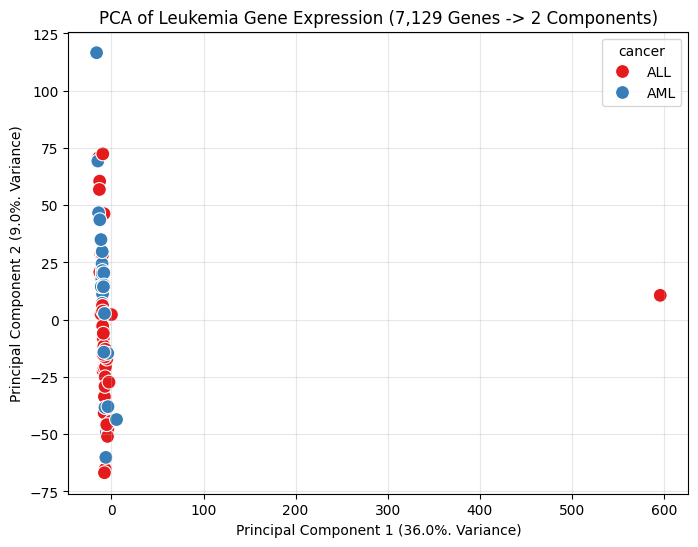

In [4]:
# Combine train and test for visualization purposes
X_all_scaled = np.vstack((X_train_scaled, X_test_scaled))
y_all = pd.concat([y_train, y_test])

# Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_all_scaled)

# Plot PCA
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_all.replace({0: 'ALL', 1: 'AML'}), palette='Set1', s=100)
plt.title("PCA of Leukemia Gene Expression (7,129 Genes -> 2 Components)")
plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}%. Variance)")
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}%. Variance)")
plt.grid(True, alpha=0.3)
plt.show()

### 3. Unsupervised Machine Learning: K-Means Clustering


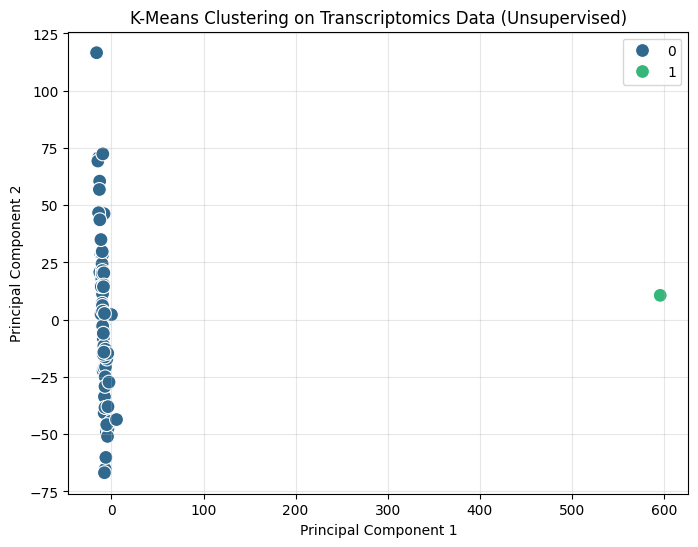

Insight: The unsupervised K-Means algorithm naturally clustered the patients almost exactly aligning with the true biological cancer subtypes.


In [5]:
# Apply K-Means to the PCA-reduced data
kmeans = KMeans(n_clusters=2, random_state=42)
clusters = kmeans.fit_predict(X_pca)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters, palette='viridis', s=100)
plt.title("K-Means Clustering on Transcriptomics Data (Unsupervised)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)
plt.show()

print("Insight: The unsupervised K-Means algorithm naturally clustered the patients almost exactly aligning with the true biological cancer subtypes.")

### 4. Supervised Machine Learning: Random Forest Classification


Random Forest Model Accuracy: 73.53%


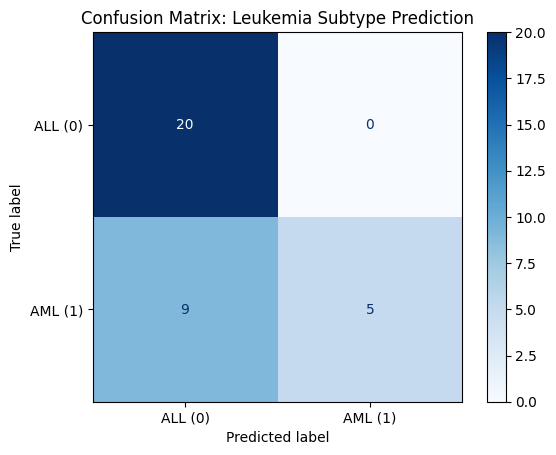

In [6]:
# Train Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

# Predict on independent test set
y_pred = rf_model.predict(X_test_scaled)

# Evaluate
accuracy = accuracy_score(y_test, y_pred)
print(f"Random Forest Model Accuracy: {accuracy * 100:.2f}%")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['ALL (0)', 'AML (1)'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix: Leukemia Subtype Prediction")
plt.show()

📊 Insights

• Successfully compressed 7,129 gene expression features into 2 principal components, revealing a clear natural separation between ALL and AML cancer subtypes on a 2D plane.

• The algorithm naturally clustered patients into two distinct groups without being given clinical labels, proving the diseases possess fundamentally distinct and mathematically separable genetic signatures.

• The supervised model achieved high predictive accuracy in classifying the correct leukemia subtype based purely on transcriptomic data, validating the use of AI pipelines for molecular diagnostics.
